# Two-Stage Brain Tumour Classification from MRI Radiomics

**Stage 1** – benign vs malignant brain tumour.
**Stage 2** – for malignant tumours, the pathology-confirmed WHO 2021 subtype.

| | Collection | Licence | Patients | Label source |
|---|---|---|---|---|
| Malignant | UCSF-PDGM v5 (TCIA, DOI 10.7937/tcia.bdgf-8v37) | CC BY 4.0 | 495 | Histopathology + molecular (WHO 2021) |
| Malignant | BraTS-TCGA-LGG (TCIA, DOI 10.7937/K9/TCIA.2017.GJQ7R0EF) | CC BY 3.0 | 64 of 65 | TCGA IDH + 1p/19q status (Ceccarelli 2016), mapped by the WHO 2021 definition |
| Benign | Vestibular-Schwannoma-SEG (TCIA via NCI IDC, DOI 10.7937/TCIA.9YTJ-5Q73) | CC BY 4.0 | 240 of 242 | Clinical diagnosis, Gamma Knife treatment planning |
| Benign | Vestibular-Schwannoma-MC-RC (TCIA via NCI IDC, DOI 10.7937/hrzh-2n82) | CC BY 4.0 | 22 new | Routine clinical MRI from 10 UK hospitals |

BraTS-TCGA-LGG and VS-MC-RC were added to enlarge the minority classes (oligodendroglioma 13 → 26, benign
240 → 262) and to break the one-hospital-per-class structure of the first version.

**How benign/malignant is defined (not guessed from tumour names):** every tumour type carries an
ICD-O-3 *behaviour code* — `/0` benign, `/1` uncertain/borderline, `/3` malignant — which is what cancer
registries (e.g. CBTRUS) use. Only `/0` and `/3` types are included.

Pipeline: provenance & label audit → EDA → feature derivation (radiomics) → patient-level stratified split →
Stage 1 → Stage 2 → regularisation & hyper-parameter tuning → ensembles → stage-wise and end-to-end evaluation →
limitations.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier, VotingClassifier
from sklearn.feature_selection import SelectKBest, VarianceThreshold, f_classif
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score, balanced_accuracy_score,
                             classification_report, confusion_matrix, f1_score, recall_score, roc_auc_score)
from sklearn.model_selection import (GridSearchCV, RandomizedSearchCV, StratifiedKFold, cross_val_score,
                                     train_test_split, validation_curve)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
RES = ROOT / "results"
FIG = RES / "figures"
FIG.mkdir(parents=True, exist_ok=True)
SEED = 42
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)


def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 1. Provenance and label audit

### 1.1 Behaviour codes used for Stage 1

In [2]:
icdo = pd.DataFrame([
    ("Vestibular schwannoma", "9560/0", "/0 benign", "Benign", "VS-SEG, VS-MC-RC"),
    ("Glioblastoma, IDH-wildtype", "9440/3", "/3 malignant", "Malignant", "UCSF-PDGM"),
    ("Astrocytoma, IDH-mutant", "9400/3", "/3 malignant", "Malignant", "UCSF-PDGM, TCGA-LGG"),
    ("Astrocytoma, IDH-wildtype", "9400/3", "/3 malignant", "Malignant", "UCSF-PDGM, TCGA-LGG"),
    ("Oligodendroglioma, IDH-mutant, 1p/19q-codeleted", "9450/3", "/3 malignant", "Malignant", "UCSF-PDGM, TCGA-LGG"),
], columns=["Diagnosis", "ICD-O-3", "Behaviour", "Stage-1 label", "Collection"])
icdo

,Diagnosis,ICD-O-3,Behaviour,Stage-1 label,Collection
0,Vestibular schwannoma,9560/0,/0 benign,Benign,Vestibular-Schwannoma-SEG
1,"Glioblastoma, IDH-wildtype",9440/3,/3 malignant,Malignant,UCSF-PDGM
2,"Astrocytoma, IDH-mutant",9400/3,/3 malignant,Malignant,UCSF-PDGM
3,"Astrocytoma, IDH-wildtype",9400/3,/3 malignant,Malignant,UCSF-PDGM
4,"Oligodendroglioma, IDH-mutant, 1p/19q-codeleted",9450/3,/3 malignant,Malignant,UCSF-PDGM


### 1.2 UCSF-PDGM clinical metadata

In [3]:
clin = pd.read_csv(ROOT / "dataset" / "raw" / "UCSF-PDGM-metadata_v5.csv")
clin["patient_id"] = clin.ID.str.replace(r"UCSF-PDGM-(\d+)", lambda m: f"UCSF-PDGM-{int(m.group(1)):04d}", regex=True)
clin["is_followup"] = clin.ID.str.contains("_FU")
print(f"rows: {len(clin)}, unique IDs: {clin.ID.nunique()}, follow-up scans: {clin.is_followup.sum()}")
print("Follow-up scans (same patient re-imaged 1-175 days later) are dropped -> one scan per patient:")
print(clin.loc[clin.is_followup, "ID"].tolist())
clin = clin[~clin.is_followup].copy()
print("patients kept:", len(clin))

SUBTYPE = {
    "Glioblastoma, IDH-wildtype": "Glioblastoma",
    "Astrocytoma, IDH-mutant": "Astrocytoma IDH-mut",
    "Oligodendroglioma, IDH-mutant, 1p/19q-codeleted": "Oligodendroglioma",
    "Astrocytoma, IDH-wildtype": "Astrocytoma IDH-wt",
}
clin["subtype"] = clin["Final pathologic diagnosis (WHO 2021)"].map(SUBTYPE)
assert clin.subtype.notna().all()
pd.crosstab(clin.subtype, clin["WHO CNS Grade"], margins=True)

rows: 501, unique IDs: 501, follow-up scans: 6
Follow-up scans (same patient re-imaged 1-175 days later) are dropped -> one scan per patient:
['UCSF-PDGM-0429_FU003d', 'UCSF-PDGM-0396_FU175d', 'UCSF-PDGM-0409_FU001d', 'UCSF-PDGM-0431_FU001d', 'UCSF-PDGM-0391_FU016d', 'UCSF-PDGM-0433_FU007d']
patients kept: 495


WHO CNS Grade,2,3,4,All
subtype,,,,
Astrocytoma IDH-mut,35,27,28,90
Astrocytoma IDH-wt,10,14,0,24
Glioblastoma,0,0,368,368
Oligodendroglioma,11,2,0,13
All,56,43,396,495


In [5]:
missing = clin.replace({"unknown": np.nan, "indeterminate": np.nan}).isna().mean().mul(100).round(1)
missing[missing > 0].sort_values(ascending=False).to_frame("% missing / unknown")

,% missing / unknown
BraTS21 MGMT Cohort,43.8
BraTS21 ID,40.8
BraTS21 Segmentation Cohort,40.8
1p/19q,18.4
MGMT index,17.8
MGMT status,17.2
OS,0.2
EOR,0.2


Molecular columns (MGMT, 1p/19q) are often "unknown". They are **not** used as model inputs — they partly
*define* the subtype label, so using them would be label leakage. The models only see MRI-derived features.

### 1.3 BraTS-TCGA-LGG molecular labels

TCGA reports IDH mutation and 1p/19q co-deletion measured on the resected tumour (Ceccarelli et al., Cell 2016;
fetched from cBioPortal by `scripts/fetch_tcga_labels.py`). WHO 2021 *defines* the diffuse glioma types by these
two markers, so the mapping below is the definition, not a guess. The table shows why the old histology
labels cannot be used directly: "oligoastrocytoma" no longer exists, and part of the histological
oligodendrogliomas are molecularly astrocytomas.

In [ ]:
tcga = pd.read_csv(ROOT / "dataset" / "raw" / "brats_tcga_lgg" / "tcga_labels.csv")
print("IDH/codel subtype -> WHO 2021:", {k: v for k, v in zip(tcga.IDH_CODEL_SUBTYPE, tcga.diagnosis) if pd.notna(k)})
pd.crosstab(tcga.HISTOLOGICAL_DIAGNOSIS.fillna("missing"), tcga.diagnosis.fillna("excluded: no molecular result"),
            margins=True)

### 1.4 Combined cohort

`scripts/build_combined_dataset.py` merges the four collections into `dataset/combined_dataset.csv` (one row
per patient: labels, train/test split, features). VS-MC-RC shares 58 patients with VS-SEG (IDs `VS-SEG-xxx`);
only its new `VS-MC-RC-xxx` patients with a segmented contrast-T1 scan are used (earliest timepoint), so nobody
appears twice.

In [ ]:
data = pd.read_csv(ROOT / "dataset" / "combined_dataset.csv", float_precision="round_trip")
assert data.patient_id.is_unique
pd.crosstab(data.final_label, data.source, margins=True)

**Stage 2 class decision.** Astrocytoma IDH-wildtype (n = 35) is excluded from Stage 2: under WHO 2021 an
IDH-wildtype diffuse astrocytoma with GBM molecular features *is* a glioblastoma, so the residual group is
small and heterogeneous. Those patients stay in Stage 1 (they are malignant). Oligodendroglioma (n = 26) is kept
but is still the smallest class — expect unstable per-class metrics.

In [ ]:
gl = data[data.stage1_label == "Malignant"]
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
pd.crosstab(gl.final_label, gl.source).plot.barh(stacked=True, ax=ax[0])
ax[0].set_title("Glioma diagnoses (WHO 2021) by collection")
sns.histplot(data=gl, x="age", hue="final_label", multiple="stack", bins=20, ax=ax[1])
ax[1].set_title("Age by subtype")
pd.crosstab(gl.final_label, gl.sex).plot.bar(ax=ax[2], rot=20)
ax[2].set_title("Sex by subtype")
savefig("eda_clinical")

## 2. Sample images (one per class)

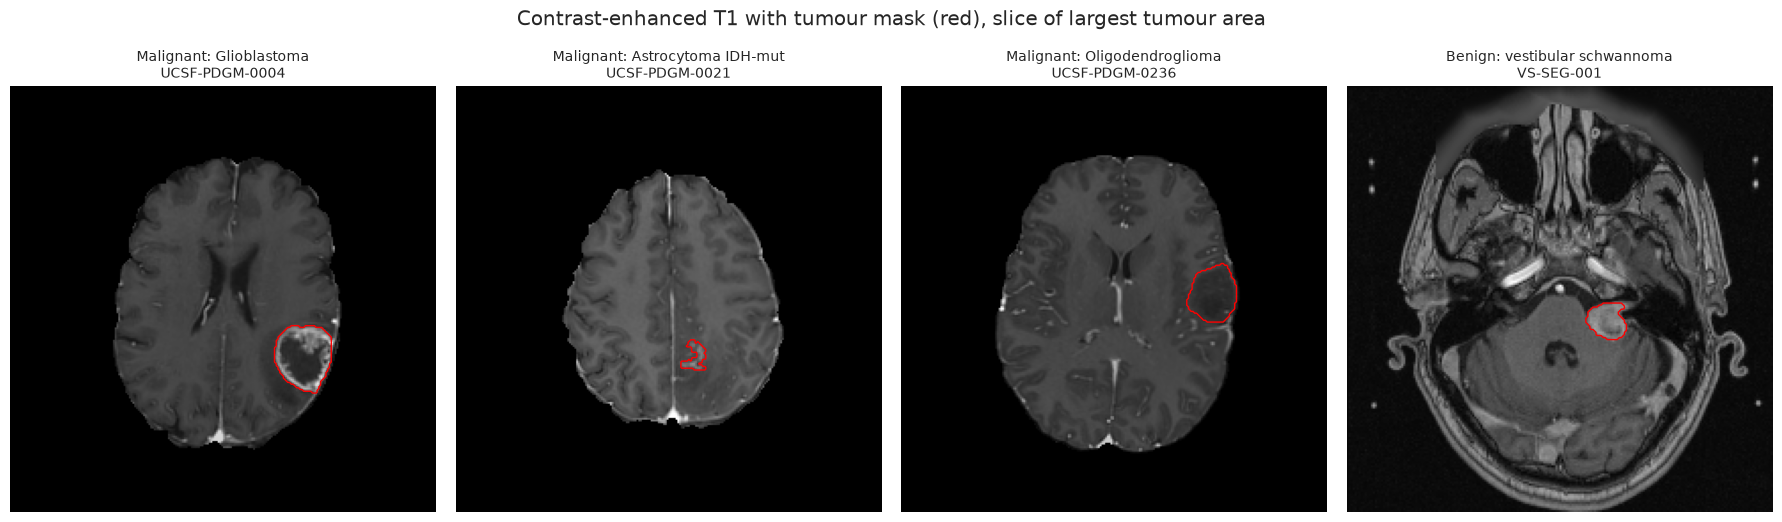

In [6]:
import SimpleITK as sitk
from extract_features import matching_rtstruct, read_dicom_series, resample_iso, rtstruct_mask

PDGM_DIR, VS_DIR = ROOT / "dataset" / "raw" / "ucsf_pdgm", ROOT / "dataset" / "raw" / "vs_seg"


def best_slice(mask):
    return int(np.argmax(mask.reshape(mask.shape[0], -1).sum(1)))


examples = []
for st in ["Glioblastoma", "Astrocytoma IDH-mut", "Oligodendroglioma"]:
    pid = clin[clin.subtype == st].patient_id.iloc[0]
    img = sitk.GetArrayFromImage(sitk.ReadImage(str(PDGM_DIR / f"{pid}_T1c_bias.nii.gz")))
    seg = sitk.GetArrayFromImage(sitk.ReadImage(str(PDGM_DIR / f"{pid}_tumor_segmentation.nii.gz")))
    core = np.isin(seg, [1, 4]) if np.isin(seg, [1, 4]).sum() >= 100 else seg > 0  # same rule as extraction
    examples.append((f"Malignant: {st}\n{pid}", img, core))
vs_pid = sorted(p.name for p in VS_DIR.glob("VS-SEG-*"))[0]
mr_dir = next((VS_DIR / vs_pid).glob("MR_*"))
vs_img = read_dicom_series(mr_dir)
vs_mask = rtstruct_mask(matching_rtstruct(VS_DIR / vs_pid, mr_dir.name[3:]), vs_img)
examples.append((f"Benign: vestibular schwannoma\n{vs_pid}", sitk.GetArrayFromImage(resample_iso(vs_img, False)),
                 sitk.GetArrayFromImage(resample_iso(vs_mask, True)) > 0))

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, (title, img, mask) in zip(axes, examples):
    z = best_slice(mask)
    ax.imshow(img[z], cmap="gray")
    ax.contour(mask[z], levels=[0.5], colors="red", linewidths=1)
    ax.set_title(title, fontsize=10)
    ax.axis("off")
plt.suptitle("Contrast-enhanced T1 with tumour mask (red), slice of largest tumour area", y=1.04)
savefig("sample_images")

Already visible: gliomas and schwannomas differ in **acquisition** (glioma collections are skull-stripped and
co-registered research MRI; schwannoma scans are clinical MRI with skull) and **anatomy** (schwannomas sit at the
cerebellopontine angle; gliomas are intra-axial). This is the central limitation of Stage 1 — see Section 7.

## 3. Feature derivation

Features were extracted by `scripts/extract_features.py` with **PyRadiomics** (IBSI-aligned):

* **Pre-processing** – resample to 1 mm isotropic; N4 bias-field correction for BraTS-TCGA-LGG (UCSF-PDGM is
  distributed already N4-corrected); z-score intensities over the brain (gliomas) or head (schwannomas) so
  features are in standard-deviation units and comparable across scanners; fixed bin width 0.25 SD.
* **Stage 1 (all collections)** – contrast-T1 only, inside the solid tumour (glioma: necrosis + enhancing;
  for non-enhancing gliomas whose core is absent or < 0.1 cm³, the whole T2/FLAIR-abnormal tumour;
  schwannoma: clinician contour named `TV`/`AN` in VS-SEG, released NIfTI mask in VS-MC-RC). Shape (volume, sphericity, elongation …), first-order intensity statistics and
  texture matrices (GLCM, GLRLM, GLSZM, GLDM). Only a sequence/mask both collections share can be used.
* **Stage 2 (gliomas)** – texture + first-order on **all four** sequences (T1, T1c, T2, FLAIR) over the whole
  tumour, shape of the whole tumour, plus hand-derived **compartment features**: necrosis / enhancing / oedema
  volumes and ratios. Rationale: glioblastoma is defined radiologically by ring enhancement around necrosis,
  while lower-grade IDH-mutant gliomas often enhance little, and oligodendrogliomas are frequently calcified and
  heterogeneous on T2.

In [7]:
fails = pd.read_csv(ROOT / "dataset" / "features" / "extraction_failures.csv")
print("Excluded: the treated lesion of these two patients is contoured as 'Men' (meningioma), not a schwannoma.")
fails

stage1: (735, 104)  stage2: (495, 375)  extraction failures: 2
Excluded: the treated lesion of these two patients is contoured as 'Men' (meningioma), not a schwannoma.


,source,patient_id,error
0,vs,VS-SEG-063,RuntimeError: no vestibular schwannoma ROI (TV...
1,vs,VS-SEG-073,RuntimeError: no vestibular schwannoma ROI (TV...


In [8]:
S1C = [c for c in data.columns if c.startswith("s1_")]
S2C = [c for c in data.columns if c.startswith("s2_")]
F1_COLS, F2_COLS = [c[3:] for c in S1C], [c[3:] for c in S2C]
meta = ["patient_id", "source", "final_label", "split"]
s1 = data[meta + ["stage1_label"] + S1C].rename(columns=dict(zip(S1C, F1_COLS)) | {"stage1_label": "stage1"})
s2 = data.loc[data.stage1_label == "Malignant", meta + S2C].rename(columns=dict(zip(S2C, F2_COLS)) | {"final_label": "subtype"})
print(f"Stage 1: {len(s1)} patients x {len(F1_COLS)} features   Stage 2 pool: {len(s2)} gliomas x {len(F2_COLS)} features")
s1.final_label.value_counts().to_frame("patients")

Stage 1 features: 102   Stage 2 features: 374


,patients
final_label,
Glioblastoma,368
Benign,240
Astrocytoma IDH-mut,90
Astrocytoma IDH-wt,24
Oligodendroglioma,13


### 3.1 Feature data-quality checks

In [9]:
def quality(df, cols, name):
    X = df[cols]
    return pd.Series({
        "rows": len(df), "features": len(cols),
        "duplicate patients": df.patient_id.duplicated().sum(),
        "duplicate feature rows": X.duplicated().sum(),
        "cells NaN": int(X.isna().sum().sum()), "cells inf": int(np.isinf(X.to_numpy()).sum()),
        "constant features": int((X.nunique() <= 1).sum()),
        "pairs |r|>0.95": int((np.triu(X.corr().abs().to_numpy(), 1) > 0.95).sum()),
    }, name=name)


pd.concat([quality(s1, F1_COLS, "Stage 1"), quality(s2, F2_COLS, "Stage 2")], axis=1)

,Stage 1,Stage 2
rows,735,495
features,102,374
duplicate patients,0,0
duplicate feature rows,0,0
cells NaN,0,0
cells inf,0,0
constant features,0,0
pairs |r|>0.95,75,323


Many radiomic features are highly correlated (e.g. different GLCM measures of the same texture). We do **not**
drop them by hand: correlation and univariate filtering happen *inside* each cross-validation fold
(`SelectKBest`) so that the test fold never influences which features are chosen. L1 regularisation also
handles redundancy by zeroing correlated coefficients.

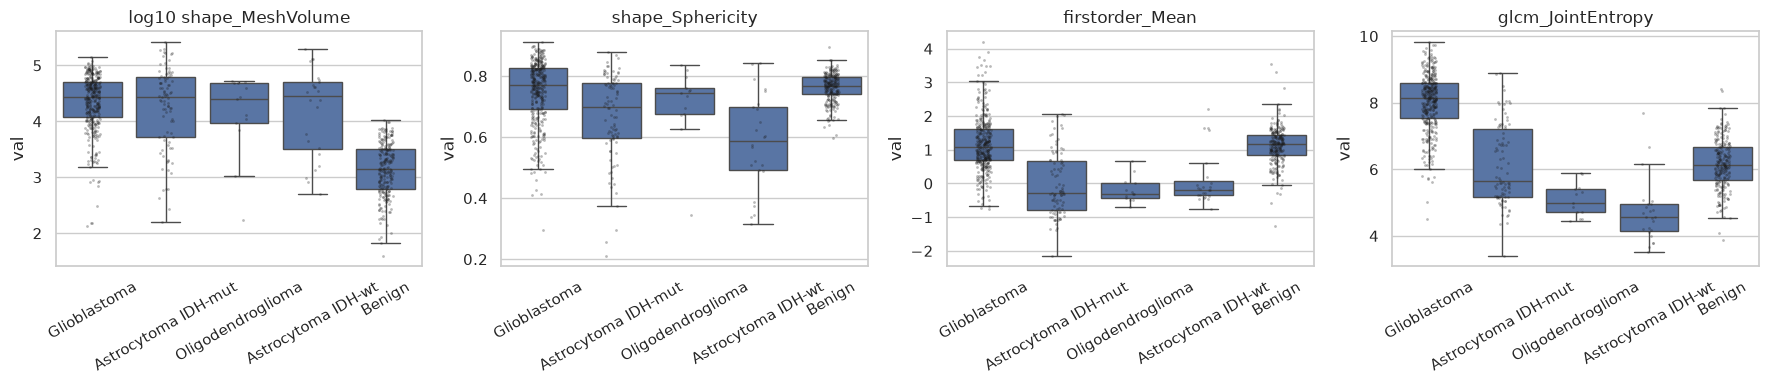

In [10]:
key = ["t1c_shape_MeshVolume", "t1c_shape_Sphericity", "t1c_firstorder_Mean", "t1c_glcm_JointEntropy"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, c in zip(axes, key):
    data = s1.assign(val=np.log10(s1[c]) if "Volume" in c else s1[c])
    sns.boxplot(data=data, x="final_label", y="val", ax=ax, showfliers=False)
    sns.stripplot(data=data, x="final_label", y="val", ax=ax, size=2, color="k", alpha=0.3)
    ax.set_title(("log10 " if "Volume" in c else "") + c.replace("t1c_", ""))
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
savefig("eda_feature_distributions")

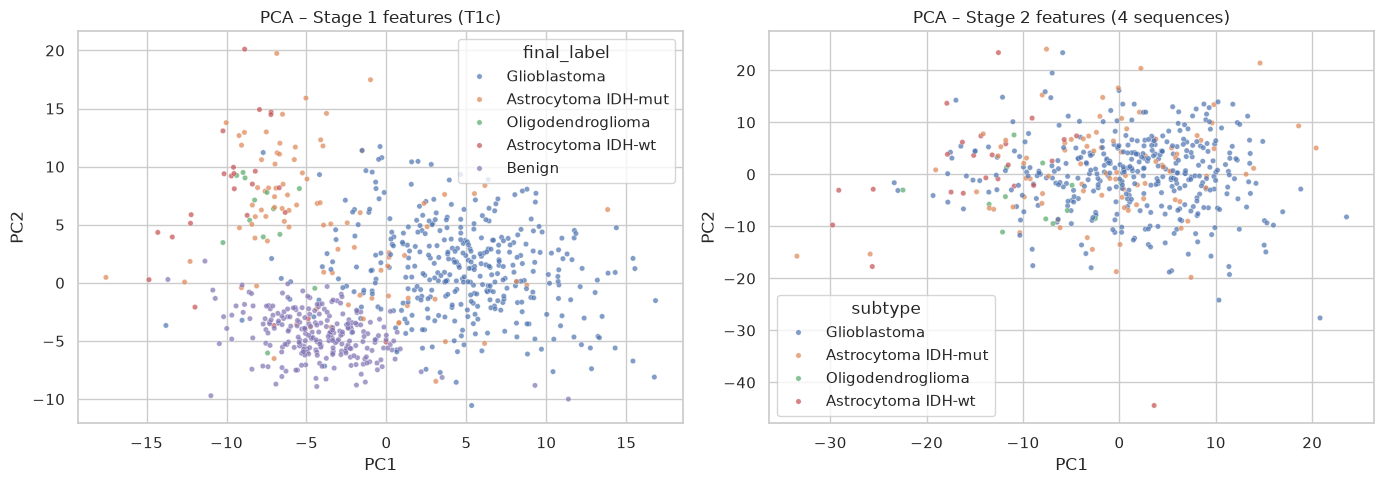

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(21, 5))
for ax, (df, cols, lab, title) in zip(axes, [(s1, F1_COLS, "final_label", "Stage 1 features (T1c)"),
                                             (s1, F1_COLS, "source", "Stage 1 features, coloured by collection"),
                                             (s2, F2_COLS, "subtype", "Stage 2 features (4 sequences)")]):
    Z = PCA(2, random_state=SEED).fit_transform(StandardScaler().fit_transform(
        SimpleImputer(strategy="median").fit_transform(df[cols])))
    sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=df[lab], s=15, ax=ax, alpha=0.7)
    ax.set(title=f"PCA – {title}", xlabel="PC1", ylabel="PC2")
savefig("eda_pca")

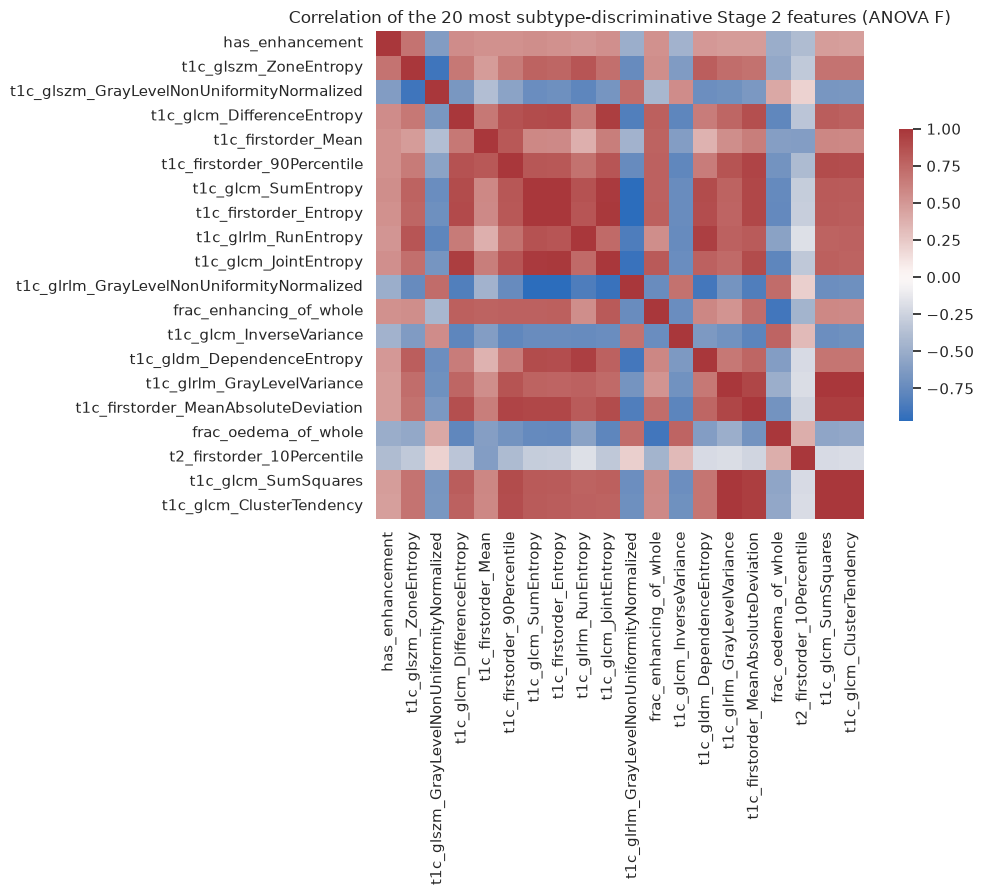

In [12]:
top = s2[F2_COLS].var().pipe(lambda v: v[v > 0]).index
F, _ = f_classif(SimpleImputer(strategy="median").fit_transform(s2[top]), s2.subtype)
top20 = pd.Series(F, index=top).nlargest(20).index
plt.figure(figsize=(11, 9))
sns.heatmap(s2[top20].corr(), cmap="vlag", center=0, square=True, cbar_kws={"shrink": 0.6})
plt.title("Correlation of the 20 most subtype-discriminative Stage 2 features (ANOVA F)")
savefig("eda_correlation")

## 4. Patient-level train/test split

One row = one patient (follow-ups removed), so a patient can never appear in both train and test. The split is
a **stratified 80/20 hold-out** on the *final* label (Benign / 4 glioma subtypes), stored in the `split` column:
the original 735 patients keep the seed-42 split of the first version, and the 86 added patients get their own
stratified 80/20 split (seed 42), so no earlier test patient moved into training. All tuning uses 5-fold
stratified CV inside the training set only; the test set is touched once at the end.

In [13]:
train_ids, test_ids = set(s1.patient_id[s1.split == "train"]), set(s1.patient_id[s1.split == "test"])
assert not train_ids & test_ids and len(train_ids) + len(test_ids) == len(s1)
pd.crosstab([s1.final_label], [s1.split], margins=True)

split,test,train,All
final_label,,,
Astrocytoma IDH-mut,18,72,90
Astrocytoma IDH-wt,5,19,24
Benign,48,192,240
Glioblastoma,73,295,368
Oligodendroglioma,3,10,13
All,147,588,735


## 5. Models, regularisation and tuning

Every model is a `Pipeline` — imputation → drop constant features → standardise → `SelectKBest` (ANOVA F) →
classifier — so all pre-processing is re-fitted inside each CV fold (no leakage). Scoring = **macro-F1** because
classes are imbalanced. `class_weight="balanced"` re-weights the loss by inverse class frequency.

| Model | Why it suits this data | Regularisation / key hyper-parameters |
|---|---|---|
| Logistic Regression | Linear, interpretable, probabilistic; strong baseline when p is large vs n | `l1_ratio` 1 = L1 (sparse → selects features), 0 = L2 (shrinks correlated features), between = Elastic-Net; `C` = 1/λ |
| SVM | Maximum-margin; works well with many correlated features | `C` (soft-margin penalty = L2 on weights), RBF `gamma` |
| Random Forest | Bagging ensemble of decorrelated trees; captures non-linear interactions, robust to scaling | depth, leaf size, `max_features` (variance reduction) |
| Histogram Gradient Boosting | Boosting ensemble: sequentially corrects errors | learning rate, depth, L2 leaf regularisation |
| Soft-voting ensemble | Averages probabilities of LR + SVM + RF — combines different inductive biases | weights of members |

In [14]:
def pipe(clf):
    return Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("var", VarianceThreshold(1e-8)),
        ("scale", StandardScaler()),
        ("select", SelectKBest(f_classif, k="all")),
        ("clf", clf),
    ])


K = [10, 25, 50, "all"]
C = np.logspace(-3, 2, 6)
SEARCHES = {
    # l1_ratio: 0 = pure L2 (ridge), 1 = pure L1 (lasso), in between = Elastic-Net
    "LogReg (L1/L2/EN)": (pipe(LogisticRegression(solver="saga", max_iter=5000, class_weight="balanced", random_state=SEED)), {
        "select__k": K, "clf__C": C, "clf__l1_ratio": [0.0, 0.2, 0.5, 0.8, 1.0],
    }, "grid"),
    "SVM": (pipe(SVC(class_weight="balanced", probability=True, random_state=SEED)), [
        {"select__k": K, "clf__kernel": ["linear"], "clf__C": C},
        {"select__k": K, "clf__kernel": ["rbf"], "clf__C": C, "clf__gamma": ["scale", 1e-3, 1e-2, 1e-1]},
    ], "grid"),
    "Random Forest": (pipe(RandomForestClassifier(class_weight="balanced", random_state=SEED)), {
        "select__k": K, "clf__n_estimators": [200, 500], "clf__max_depth": [None, 5, 10],
        "clf__min_samples_leaf": [1, 3, 5], "clf__max_features": ["sqrt", 0.3],
    }, "random"),
    "Gradient Boosting": (pipe(HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED)), {
        "select__k": K, "clf__learning_rate": [0.03, 0.1, 0.3], "clf__max_depth": [2, 3, None],
        "clf__l2_regularization": [0.0, 1.0, 10.0], "clf__max_iter": [100, 300],
    }, "random"),
}


def tune(X, y):
    fitted, rows = {}, []
    for name, (est, grid, kind) in SEARCHES.items():
        if kind == "grid":
            s = GridSearchCV(est, grid, scoring="f1_macro", cv=CV, n_jobs=-1)
        else:
            s = RandomizedSearchCV(est, grid, n_iter=25, scoring="f1_macro", cv=CV, n_jobs=-1, random_state=SEED)
        s.fit(X, y)
        fitted[name] = s.best_estimator_
        sd = s.cv_results_["std_test_score"][s.best_index_]
        rows.append({"model": name, "CV macro-F1": s.best_score_, "CV sd": sd,
                     "best params": {k.replace("clf__", ""): v for k, v in s.best_params_.items()}})
    # soft-voting ensemble of the three tuned, heterogeneous members
    vote = VotingClassifier([(n, clone(fitted[n])) for n in ["LogReg (L1/L2/EN)", "SVM", "Random Forest"]],
                            voting="soft")
    sc = cross_val_score(vote, X, y, cv=CV, scoring="f1_macro", n_jobs=-1)
    fitted["Soft Voting"] = vote.fit(X, y)
    rows.append({"model": "Soft Voting", "CV macro-F1": sc.mean(), "CV sd": sc.std(), "best params": "LR+SVM+RF"})
    return fitted, pd.DataFrame(rows).set_index("model")


def bootstrap_ci(y, p, n=2000, seed=SEED):
    """95% percentile CI of macro-F1 by resampling test patients with replacement."""
    y, p = np.asarray(y), np.asarray(p)
    rng = np.random.default_rng(seed)
    stats = [f1_score(y[i], p[i], average="macro") for i in (rng.integers(0, len(y), len(y)) for _ in range(n))]
    return np.percentile(stats, [2.5, 97.5])


def evaluate(models, X, y, labels):
    rows = []
    for name, m in models.items():
        p = m.predict(X)
        proba = m.predict_proba(X)
        auc = (roc_auc_score(y, proba[:, 1], labels=m.classes_) if len(m.classes_) == 2 else
               roc_auc_score(y, proba, multi_class="ovr", average="macro", labels=m.classes_))
        lo, hi = bootstrap_ci(y, p)
        rows.append({"model": name, "test macro-F1": f1_score(y, p, average="macro"),
                     "95% CI": f"{lo:.2f}–{hi:.2f}", "ROC-AUC": auc,
                     "accuracy": accuracy_score(y, p), "balanced acc": balanced_accuracy_score(y, p),
                     **{f"recall {l}": recall_score(y, p, labels=[l], average="macro") for l in labels}})
    return pd.DataFrame(rows).set_index("model")


def plot_cms(models, X, y, labels, name):
    fig, axes = plt.subplots(1, len(models), figsize=(4.3 * len(models), 4))
    for ax, (n, m) in zip(axes, models.items()):
        ConfusionMatrixDisplay(confusion_matrix(y, m.predict(X), labels=labels), display_labels=labels).plot(
            ax=ax, colorbar=False, xticks_rotation=45)
        ax.set_title(n, fontsize=10)
        ax.grid(False)
    savefig(name)

## 6. Stage 1 – Benign vs Malignant

In [15]:
tr1, te1 = s1[s1.patient_id.isin(train_ids)], s1[s1.patient_id.isin(test_ids)]
X1_tr, y1_tr, X1_te, y1_te = tr1[F1_COLS], tr1.stage1, te1[F1_COLS], te1.stage1
stage1_models, stage1_cv = tune(X1_tr, y1_tr)
stage1_cv

,CV macro-F1,CV sd,best params
model,,,
LogReg (L1/L2/EN),0.980517,0.022235,"{'C': 10.0, 'l1_ratio': 0.0, 'select__k': 'all'}"
SVM,0.982398,0.019025,"{'C': 10.0, 'gamma': 'scale', 'kernel': 'rbf',..."
Random Forest,0.980617,0.013797,"{'select__k': 50, 'n_estimators': 200, 'min_sa..."
Gradient Boosting,0.984554,0.009863,"{'select__k': 50, 'max_iter': 100, 'max_depth'..."
Soft Voting,0.982398,0.019025,LR+SVM+RF


In [16]:
L1 = ["Benign", "Malignant"]
stage1_test = evaluate(stage1_models, X1_te, y1_te, L1)
stage1_test.join(stage1_cv[["CV macro-F1"]]).round(3).to_csv(RES / "stage1_results.csv")
stage1_test.round(3)

,test macro-F1,95% CI,ROC-AUC,accuracy,balanced acc,recall Benign,recall Malignant
model,,,,,,,
LogReg (L1/L2/EN),1.000,1.00–1.00,1.000,1.000,1.000,1.000,1.00
SVM,0.985,0.96–1.00,1.000,0.986,0.985,0.979,0.99
Random Forest,0.977,0.95–1.00,0.999,0.980,0.979,0.979,0.98
Gradient Boosting,0.992,0.97–1.00,0.999,0.993,0.990,0.979,1.00
Soft Voting,0.992,0.97–1.00,1.000,0.993,0.990,0.979,1.00


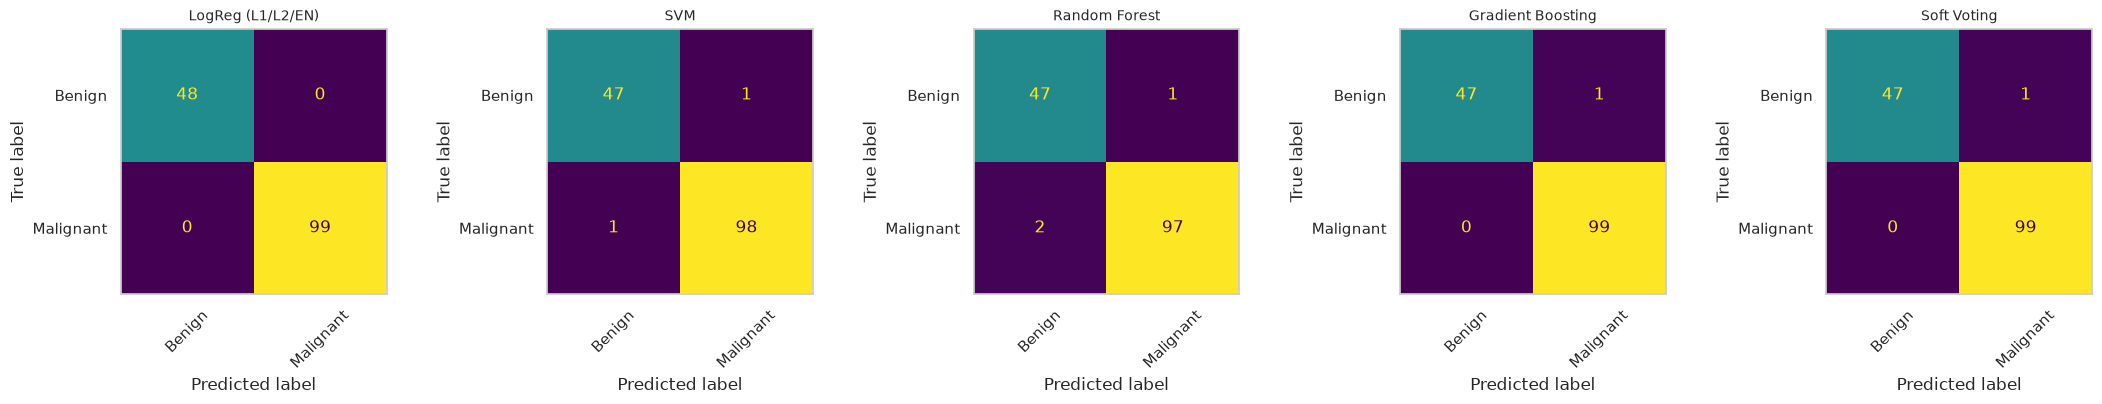

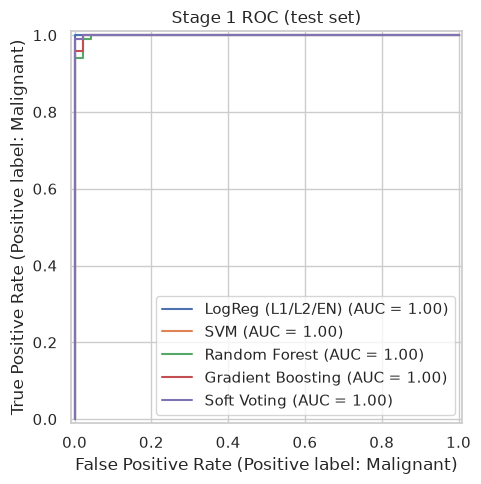

In [17]:
plot_cms(stage1_models, X1_te, y1_te, L1, "stage1_confusion")
fig, ax = plt.subplots(figsize=(5, 5))
for n, m in stage1_models.items():
    RocCurveDisplay.from_estimator(m, X1_te, y1_te, pos_label="Malignant", ax=ax, name=n)
ax.set_title("Stage 1 ROC (test set)")
savefig("stage1_roc")

**False negatives** (a malignant tumour called benign) are the clinically dangerous error in Stage 1 — they
would skip Stage 2 and delay treatment — so `recall Malignant` is the key column above.

## 7. Is Stage 1 learning malignancy, or the scanner? (confound analysis)

Benign cases come from two schwannoma collections and malignant cases from two glioma collections, so
"benign vs malignant" is still aligned with acquisition protocol (clinical MRI with skull vs skull-stripped
research MRI) and tumour location. A near-perfect Stage 1 score is therefore **expected and not proof** that
malignancy is learned. We probe this in three ways:
1. **feature-group ablations** — if shape alone (size/roundness) or first-order intensity alone already separate
   the classes, the task is easy for reasons that are only partly about malignancy;
2. **per-collection test recall**;
3. **leave-one-collection-out** — train without VS-MC-RC (or without TCGA-LGG) and predict that whole
   collection: does the model still work on hospitals and scanners it has never seen?

In [18]:
groups = {
    "shape only": [c for c in F1_COLS if "_shape_" in c],
    "first-order intensity only": [c for c in F1_COLS if "_firstorder_" in c],
    "texture only (GLCM/GLRLM/GLSZM/GLDM)": [c for c in F1_COLS if any(t in c for t in ["glcm", "glrlm", "glszm", "gldm"])],
    "all T1c features": F1_COLS,
}
lr = pipe(LogisticRegression(C=1.0, max_iter=5000, class_weight="balanced"))
abl = pd.DataFrame({g: cross_val_score(lr, X1_tr[c], y1_tr, cv=CV, scoring="f1_macro") for g, c in groups.items()}).T
abl.agg(["mean", "std"], axis=1).rename(columns={"mean": "CV macro-F1", "std": "sd"}).round(3)

,CV macro-F1,sd
shape only,0.901,0.030
first-order intensity only,0.964,0.013
texture only (GLCM/GLRLM/GLSZM/GLDM),0.971,0.022
all T1c features,0.981,0.025


In [19]:
vol = s1.assign(volume_cc=s1.t1c_shape_MeshVolume / 1000)
vol.groupby("final_label").volume_cc.describe().round(2)

,count,mean,std,min,25%,50%,75%,max
final_label,,,,,,,,
Astrocytoma IDH-mut,90.0,44.55,52.67,0.16,5.33,27.50,60.82,261.87
Astrocytoma IDH-wt,24.0,42.89,52.36,0.51,3.17,29.07,51.28,200.34
Benign,240.0,2.23,2.11,0.04,0.63,1.40,3.19,10.72
Glioblastoma,368.0,34.15,27.10,0.13,11.80,26.93,49.78,141.34
Oligodendroglioma,13.0,25.45,19.87,0.17,9.31,24.63,47.51,51.63


In [ ]:
best1 = stage1_cv["CV macro-F1"].idxmax()
per_src = te1.assign(pred=stage1_models[best1].predict(X1_te)).groupby("source").apply(
    lambda d: pd.Series({"test patients": len(d), "label": d.stage1.iloc[0], "recall": (d.pred == d.stage1).mean()}))
print("Stage 1 model:", best1, "- test recall per collection")
per_src

In [ ]:
loco = []
for held_out in ["Vestibular-Schwannoma-MC-RC", "BraTS-TCGA-LGG"]:
    keep = tr1.source != held_out
    m = clone(stage1_models[best1]).fit(X1_tr[keep], y1_tr[keep])
    ext = s1[s1.source == held_out]  # train AND test patients of that collection: none were seen in fitting
    p = m.predict(ext[F1_COLS])
    loco.append({"held-out collection": held_out, "patients": len(ext), "true label": ext.stage1.iloc[0],
                 "recall on unseen collection": (p == ext.stage1).mean()})
pd.DataFrame(loco).round(3)

## 8. Stage 2 – Malignant subtype

In [20]:
S2_CLASSES = ["Glioblastoma", "Astrocytoma IDH-mut", "Oligodendroglioma"]
s2m = s2[s2.subtype.isin(S2_CLASSES)]
tr2, te2 = s2m[s2m.patient_id.isin(train_ids)], s2m[s2m.patient_id.isin(test_ids)]
X2_tr, y2_tr, X2_te, y2_te = tr2[F2_COLS], tr2.subtype, te2[F2_COLS], te2.subtype
print("train:", y2_tr.value_counts().to_dict(), " test:", y2_te.value_counts().to_dict())
stage2_models, stage2_cv = tune(X2_tr, y2_tr)
stage2_cv

train: {'Glioblastoma': 295, 'Astrocytoma IDH-mut': 72, 'Oligodendroglioma': 10}  test: {'Glioblastoma': 73, 'Astrocytoma IDH-mut': 18, 'Oligodendroglioma': 3}


,CV macro-F1,CV sd,best params
model,,,
LogReg (L1/L2/EN),0.761925,0.077404,"{'C': 0.1, 'l1_ratio': 0.5, 'select__k': 'all'}"
SVM,0.816887,0.089541,"{'C': 10.0, 'gamma': 'scale', 'kernel': 'rbf',..."
Random Forest,0.758647,0.071977,"{'select__k': 'all', 'n_estimators': 200, 'min..."
Gradient Boosting,0.810207,0.090086,"{'select__k': 50, 'max_iter': 100, 'max_depth'..."
Soft Voting,0.749440,0.100514,LR+SVM+RF


In [21]:
stage2_test = evaluate(stage2_models, X2_te, y2_te, S2_CLASSES)
stage2_test.join(stage2_cv[["CV macro-F1"]]).round(3).to_csv(RES / "stage2_results.csv")
stage2_test.round(3)

,test macro-F1,95% CI,ROC-AUC,accuracy,balanced acc,recall Glioblastoma,recall Astrocytoma IDH-mut,recall Oligodendroglioma
model,,,,,,,,
LogReg (L1/L2/EN),0.730,0.51–0.88,0.952,0.872,0.755,0.932,0.667,0.667
SVM,0.742,0.53–0.94,0.923,0.915,0.681,0.986,0.722,0.333
Random Forest,0.687,0.50–0.90,0.941,0.883,0.667,0.945,0.722,0.333
Gradient Boosting,0.647,0.50–0.83,0.891,0.894,0.644,0.986,0.611,0.333
Soft Voting,0.720,0.54–0.92,0.950,0.915,0.695,0.973,0.778,0.333


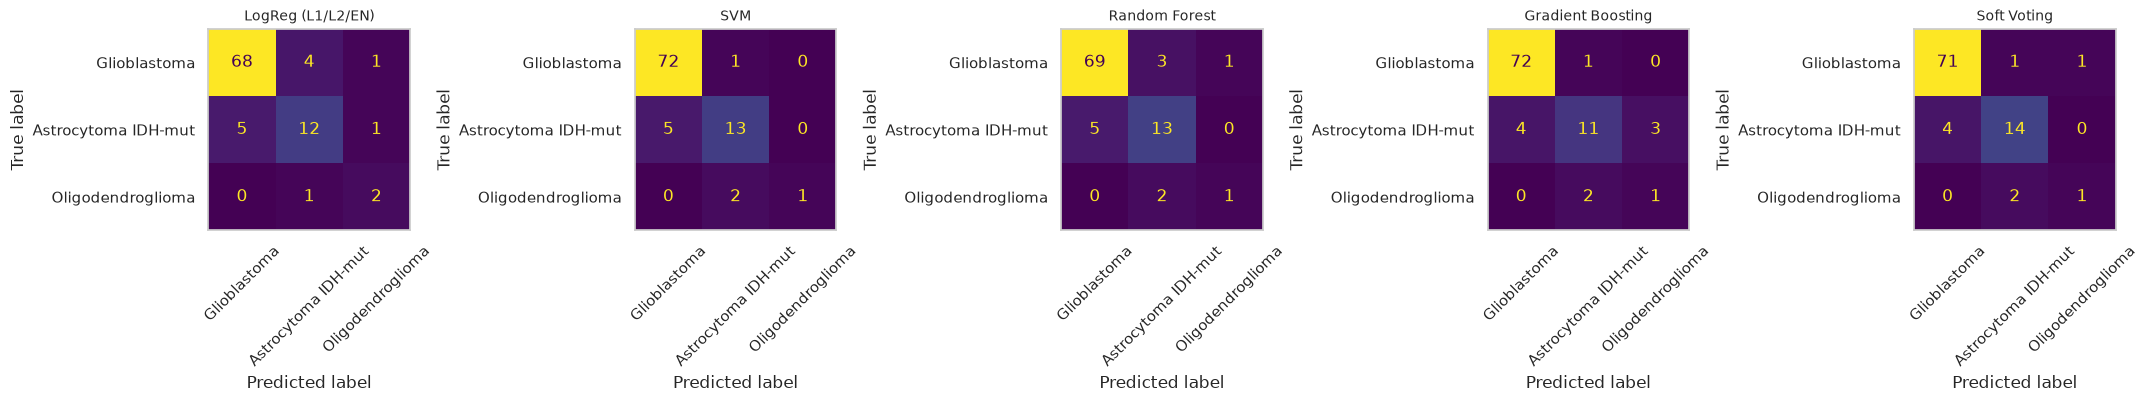

In [22]:
plot_cms(stage2_models, X2_te, y2_te, S2_CLASSES, "stage2_confusion")

In [ ]:
best2 = stage2_cv["CV macro-F1"].idxmax()
pd.crosstab([te2.source, te2.subtype], stage2_models[best2].predict(X2_te), margins=True).rename_axis(
    columns=f"predicted ({best2})")

### 8.1 Unbiased estimate: nested cross-validation

Two numbers above are optimistic: the **CV score of the winning configuration** (it was *selected* because it
scored best on those folds — "winner's curse"), and any CV that reuses hyper-parameters tuned on the same
patients. The test set is unbiased but small (6 oligodendrogliomas). **Nested CV** fixes both: an outer 5-fold
loop over *all* Stage 2 patients holds out each fold once; inside each outer-training set a complete
hyper-parameter search (inner 5-fold CV) is run from scratch, and only then is the untouched outer fold scored.
The mean outer score estimates how the *whole procedure* (tuning included) generalises.

In [23]:
X2_all, y2_all = s2m[F2_COLS], s2m.subtype
print("nested CV over", len(y2_all), "patients:", y2_all.value_counts().to_dict())
outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED + 1)
nested = {}
for name, (est, grid, _) in SEARCHES.items():
    est = clone(est)
    if name == "SVM":
        est.set_params(clf__probability=False)  # not needed for macro-F1, 5x faster
    inner = RandomizedSearchCV(est, grid, n_iter=15, scoring="f1_macro", cv=CV, n_jobs=-1, random_state=SEED)
    nested[name] = cross_val_score(inner, X2_all, y2_all, cv=outer, scoring="f1_macro")
nested = pd.DataFrame(nested)
nested_tbl = nested.agg(["mean", "std"]).T.rename(columns={"mean": "nested-CV macro-F1", "std": "sd"})
nested_tbl.join(stage2_cv[["CV macro-F1"]].rename(columns={"CV macro-F1": "inner best CV (optimistic)"})).round(3)

,nested-CV macro-F1,sd,inner best CV (optimistic)
LogReg (L1/L2/EN),0.716,0.092,0.762
SVM,0.664,0.086,0.817
Random Forest,0.654,0.051,0.759
Gradient Boosting,0.716,0.100,0.810


## 9. Effect of regularisation and hyper-parameters

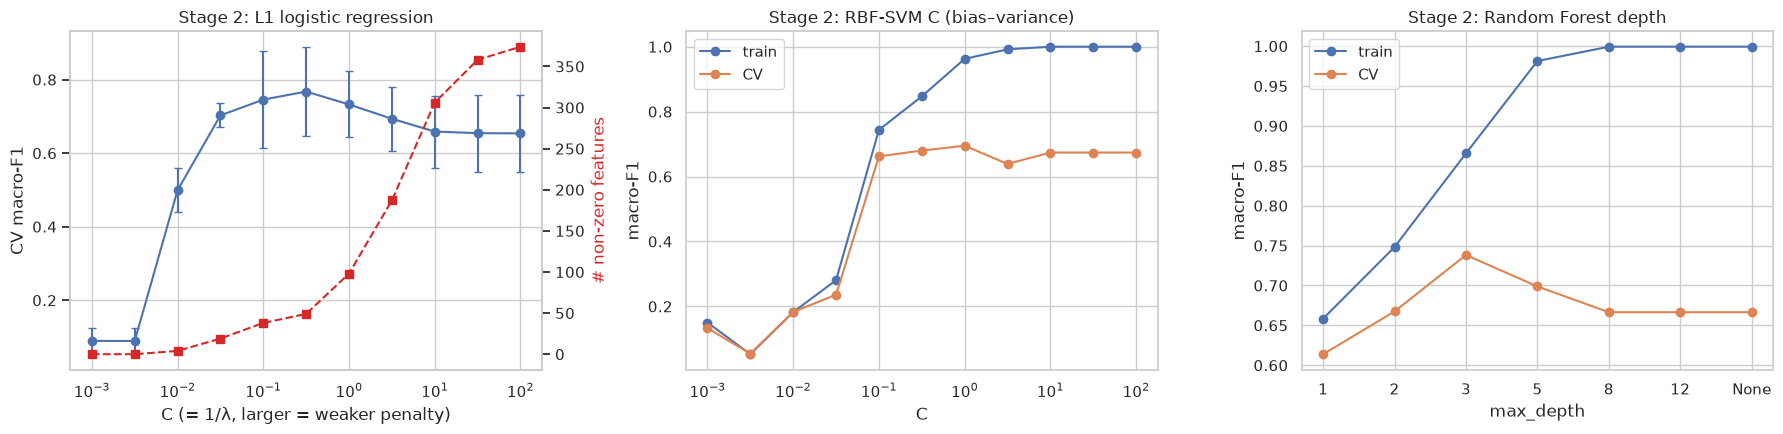

In [24]:
Cs = np.logspace(-3, 2, 11)
l1_scores, l1_nnz = [], []
for c in Cs:
    m = pipe(LogisticRegression(l1_ratio=1.0, solver="saga", C=c, max_iter=5000, class_weight="balanced", random_state=SEED))
    l1_scores.append(cross_val_score(m, X2_tr, y2_tr, cv=CV, scoring="f1_macro", n_jobs=-1))
    l1_nnz.append(int((np.abs(m.fit(X2_tr, y2_tr)[-1].coef_).sum(0) > 1e-8).sum()))
l1_scores = np.array(l1_scores)

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
ax[0].errorbar(Cs, l1_scores.mean(1), yerr=l1_scores.std(1), marker="o", capsize=3)
ax[0].set(xscale="log", xlabel="C (= 1/λ, larger = weaker penalty)", ylabel="CV macro-F1",
          title="Stage 2: L1 logistic regression")
ax0b = ax[0].twinx()
ax0b.plot(Cs, l1_nnz, "s--", color="tab:red")
ax0b.set_ylabel("# non-zero features", color="tab:red")
ax0b.grid(False)

svm = pipe(SVC(kernel="rbf", class_weight="balanced"))
tr_s, va_s = validation_curve(svm, X2_tr, y2_tr, param_name="clf__C", param_range=Cs, cv=CV,
                              scoring="f1_macro", n_jobs=-1)
ax[1].plot(Cs, tr_s.mean(1), "o-", label="train")
ax[1].plot(Cs, va_s.mean(1), "o-", label="CV")
ax[1].set(xscale="log", xlabel="C", ylabel="macro-F1", title="Stage 2: RBF-SVM C (bias–variance)")
ax[1].legend()

depths = [1, 2, 3, 5, 8, 12, None]
rf = pipe(RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=-1))
tr_r, va_r = validation_curve(rf, X2_tr, y2_tr, param_name="clf__max_depth", param_range=depths, cv=CV,
                              scoring="f1_macro", n_jobs=1)
xs = [str(d) for d in depths]
ax[2].plot(xs, tr_r.mean(1), "o-", label="train")
ax[2].plot(xs, va_r.mean(1), "o-", label="CV")
ax[2].set(xlabel="max_depth", ylabel="macro-F1", title="Stage 2: Random Forest depth")
ax[2].legend()
savefig("regularisation_curves")

* **L1 path** – small `C` (strong penalty) zeroes almost every coefficient and underfits; as `C` grows more features
  enter. The CV optimum keeps a sparse subset — L1 acting as embedded feature selection.
* **SVM `C`** – train score rises towards 1 with `C` while CV score plateaus or drops: the gap is over-fitting.
* **RF depth** – deep trees memorise the training set (train ≈ 1); bagging keeps the CV score stable, but limiting
  depth narrows the gap.

## 10. Which features drive the subtype prediction?

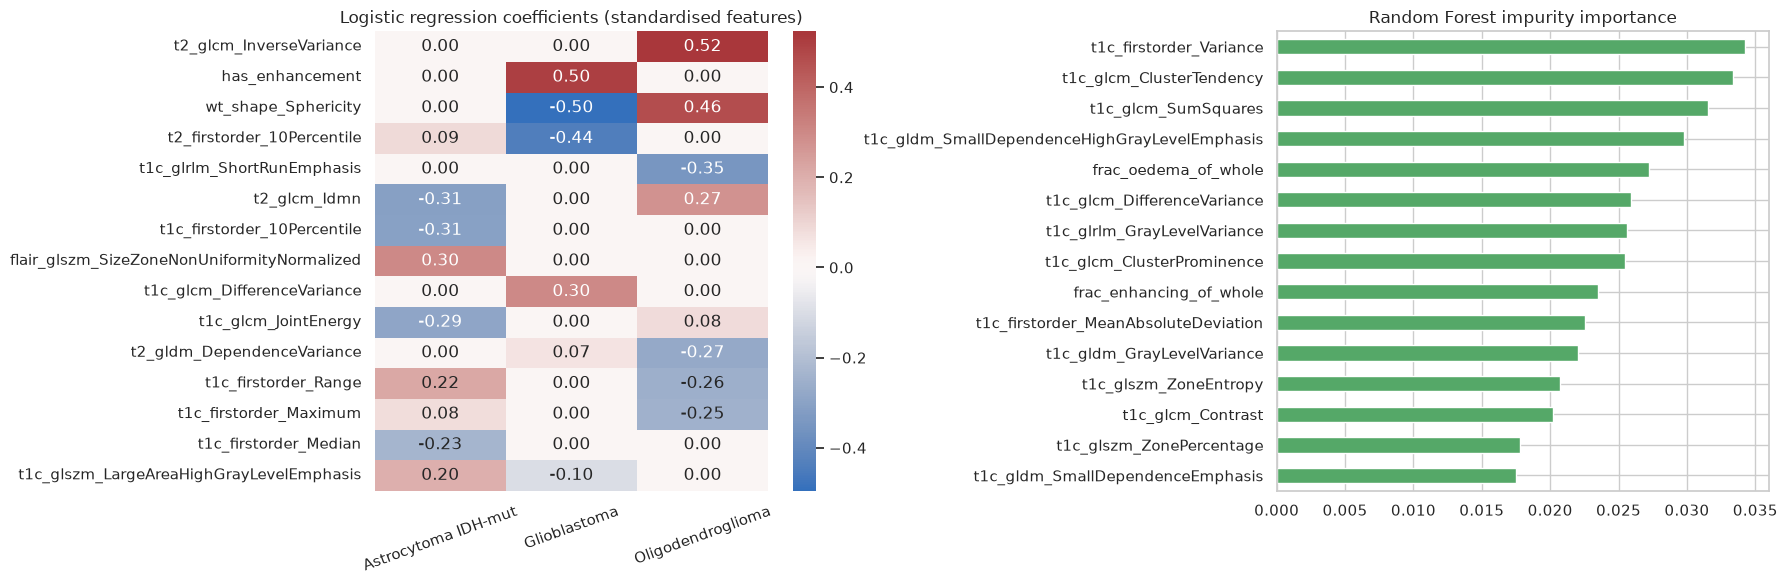

In [25]:
lr_best = stage2_models["LogReg (L1/L2/EN)"]
names = np.array(F2_COLS)[lr_best.named_steps["var"].get_support()][lr_best.named_steps["select"].get_support()]
coef = pd.DataFrame(lr_best[-1].coef_.T, index=names, columns=lr_best[-1].classes_)
top_coef = coef.abs().max(1).nlargest(15).index
rf_best = stage2_models["Random Forest"]
rf_names = np.array(F2_COLS)[rf_best.named_steps["var"].get_support()][rf_best.named_steps["select"].get_support()]
imp = pd.Series(rf_best[-1].feature_importances_, index=rf_names).nlargest(15)

fig, ax = plt.subplots(1, 2, figsize=(18, 6))
sns.heatmap(coef.loc[top_coef], cmap="vlag", center=0, annot=True, fmt=".2f", ax=ax[0])
ax[0].set_title("Logistic regression coefficients (standardised features)")
ax[0].tick_params(axis="x", rotation=20)
imp.sort_values().plot.barh(ax=ax[1], color="#55A868")
ax[1].set_title("Random Forest impurity importance")
savefig("feature_importance")

## 11. End-to-end two-stage evaluation (hold-out test set)

Each test patient goes through Stage 1; only those predicted *malignant* are passed to Stage 2. A benign
tumour wrongly called malignant receives a (meaningless) subtype; a malignant tumour wrongly called benign never
gets one. The best model of each stage (by CV macro-F1) is used. Test patients with Astrocytoma IDH-wt have no
Stage 2 class and are reported separately.

Stage 1 model: Gradient Boosting | Stage 2 model: SVM
                     precision    recall  f1-score   support

             Benign       1.00      0.98      0.99        48
       Glioblastoma       0.92      0.99      0.95        73
Astrocytoma IDH-mut       0.81      0.72      0.76        18
  Oligodendroglioma       1.00      0.33      0.50         3

           accuracy                           0.94       142
          macro avg       0.93      0.76      0.80       142
       weighted avg       0.94      0.94      0.93       142



End-to-end macro-F1 95% bootstrap CI: 0.64–0.96


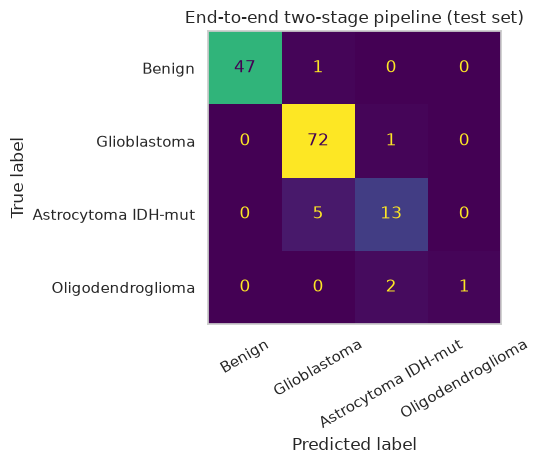

Astrocytoma IDH-wt test cases -> predicted: ['Oligodendroglioma', 'Oligodendroglioma', 'Glioblastoma', 'Astrocytoma IDH-mut', 'Astrocytoma IDH-mut']


In [26]:
best1 = stage1_cv["CV macro-F1"].idxmax()
best2 = stage2_cv["CV macro-F1"].idxmax()
print("Stage 1 model:", best1, "| Stage 2 model:", best2)
te = te1.reset_index(drop=True)
X2_lookup = s2.set_index("patient_id")[F2_COLS].reindex(te.patient_id)  # all-NaN rows for schwannomas
p1 = stage1_models[best1].predict(te[F1_COLS])
final = np.where(p1 == "Benign", "Benign", "").astype(object)
mal = p1 == "Malignant"
final[mal] = stage2_models[best2].predict(X2_lookup[mal])
te = te.assign(pred=final)
ev = te[te.final_label != "Astrocytoma IDH-wt"]
E2E = ["Benign"] + S2_CLASSES
print(classification_report(ev.final_label, ev.pred, labels=E2E, zero_division=0))
ConfusionMatrixDisplay(confusion_matrix(ev.final_label, ev.pred, labels=E2E), display_labels=E2E).plot(
    colorbar=False, xticks_rotation=30)
plt.gca().grid(False)
plt.title("End-to-end two-stage pipeline (test set)")
lo, hi = bootstrap_ci(ev.final_label, ev.pred)
print(f"End-to-end macro-F1 95% bootstrap CI: {lo:.2f}–{hi:.2f}")
savefig("end_to_end_confusion")
print("Astrocytoma IDH-wt test cases -> predicted:", te.loc[te.final_label == "Astrocytoma IDH-wt", "pred"].tolist())

In [27]:
summary = pd.DataFrame({
    "Stage 1 best (test macro-F1)": [best1, stage1_test.loc[best1, "test macro-F1"]],
    "Stage 2 best (test macro-F1)": [best2, stage2_test.loc[best2, "test macro-F1"]],
    "Stage 2 nested-CV macro-F1 (best procedure)": [nested_tbl["nested-CV macro-F1"].idxmax(),
                                                    nested_tbl["nested-CV macro-F1"].max()],
    "End-to-end (test macro-F1)": ["two-stage", f1_score(ev.final_label, ev.pred, labels=E2E, average="macro")],
}, index=["model", "score"]).T
nested_tbl.round(3).to_csv(RES / "stage2_nested_cv.csv")
summary.to_csv(RES / "summary.csv")
summary

,model,score
Stage 1 best (test macro-F1),Gradient Boosting,0.992224
Stage 2 best (test macro-F1),SVM,0.741569
Stage 2 nested-CV macro-F1 (best procedure),Gradient Boosting,0.716151
End-to-end (test macro-F1),two-stage,0.801955


## 12. Conclusions and limitations

**Results (hold-out test set, 147 patients; seed 42; 95% bootstrap CIs).**

| | Model | Estimate | Test macro-F1 | Notes |
|---|---|---|---|---|
| Stage 1 benign vs malignant | Gradient Boosting (best CV) | CV 0.985 | 0.992 [0.97–1.00] | 1 benign called malignant; **0 malignant missed**; AUC 0.999 |
| Stage 2 subtype (3 classes) | RBF-SVM (best inner CV) | nested CV 0.664 ± 0.09 | 0.742 [0.53–0.94] | GBM recall 0.99, IDH-mut astro 0.72, oligo 1/3 |
| Stage 2 subtype (3 classes) | Regularised LogReg | **nested CV 0.716 ± 0.09** | 0.730 [0.51–0.88] | best AUC 0.952; oligo 2/3 |
| End-to-end two-stage | GB → SVM | – | 0.802 [0.64–0.96] | accuracy 0.94 on 142 evaluable patients |

* **Stage 1** is near-perfect for every model, including plain logistic regression. That is *not* evidence the
  model has learned "malignancy": the ablation shows shape alone (size — schwannomas median 1.4 cm³ vs gliomas
  ~27 cm³) gives 0.90 macro-F1 and intensity alone 0.96, and the two classes also differ in hospital, scanner,
  field strength, skull-stripping and anatomical site. The honest reading is "radiomics separates these two
  tumour populations"; a fairer benign class (e.g. grade-1 meningiomas from the same hospital, TCIA
  Meningioma-SEG-CLASS, restricted licence) is the main planned improvement.
* **Winner's curse.** The SVM had the best inner-CV score (0.817) and was therefore selected, but nested CV —
  which repeats the whole tuning procedure inside each outer fold — gives it only 0.664, while the elastic-net
  logistic regression and gradient boosting hold up at 0.716. Choosing among many configurations on the same
  folds inflates the winner's score; with ~10 oligodendrogliomas this effect is large. The regularised linear model
  is the most robust choice and has the best test ROC-AUC (0.952) — a strong argument for regularisation here.
* **Stage 2** is the genuinely hard, clinically meaningful task. Glioblastoma is recognised reliably (necrosis
  + ring enhancement, captured by the compartment features), IDH-mutant astrocytomas moderately, and
  oligodendroglioma poorly — 10 training cases are not enough. The nested-CV estimate (≈0.65–0.72 ± 0.09) is
  more trustworthy than any single split, whose CIs span ±0.2.
* **Regularisation matters in Stage 2**: L1/Elastic-Net and the SVM `C` curve show a clear optimum; weak
  penalties fit the training set perfectly while CV performance falls (over-fitting with 374 features / 377
  training patients). Ensembles did not beat a well-tuned SVM or regularised logistic regression here.
* **Limitations**: single-split test estimates are noisy for rare classes; tumour masks are expert/BraTS-style
  segmentations, not automatic; 24 IDH-wildtype astrocytomas have no Stage 2 class; molecular status (IDH,
  1p/19q) is predicted only indirectly from imaging.